# Flight Delay Prediction — Phase 2 (Deep Learning)

## 1. Setup

In [1]:
import os
# PyTorch and XGBoost each ship their own OpenMP library; on macOS they crash if both start
# multi-threaded OpenMP. One OpenMP thread avoids this (PyTorch still uses 4 threads below).
os.environ["OMP_NUM_THREADS"] = "1"
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from nycflights13 import flights
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss,
                             precision_recall_curve, roc_curve)

sns.set_style("whitegrid")
os.makedirs("figures", exist_ok=True)

RANDOM_STATE = 42
torch.set_num_threads(4)   # CPU training is fast enough for this data and gives repeatable results
print("PyTorch", torch.__version__)

PyTorch 2.15.0


## 2. Data and features (same pipeline as Phase 1)

In [2]:
df = flights.copy()

# Drop cancelled / diverted flights (no arrival delay), build the target and a date column
df = df.dropna(subset=["arr_delay"]).copy()
df["delayed"] = (df["arr_delay"] >= 15).astype(int)
df["date"] = pd.to_datetime(df[["year", "month", "day"]])

# Remove everything only known after departure (data leakage) and unused ID / duplicate columns
leaky_columns = ["dep_time", "dep_delay", "arr_time", "arr_delay", "air_time"]
df = df.drop(columns=leaky_columns + ["tailnum", "flight", "time_hour", "year", "day", "hour", "minute"])

print("Flights:", len(df), " delayed share:", round(df["delayed"].mean(), 3))

Flights: 327346  delayed share: 0.245


In [3]:
# Calendar and schedule features with cyclic (sin/cos) encoding
df["day_of_week"] = df["date"].dt.dayofweek
df["dep_hour"] = df["sched_dep_time"] // 100
df["arr_hour"] = df["sched_arr_time"] // 100
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

def add_cyclic(df, col, period):
    df[f"{col}_sin"] = np.sin(2 * np.pi * df[col] / period)
    df[f"{col}_cos"] = np.cos(2 * np.pi * df[col] / period)

add_cyclic(df, "dep_hour", 24)
add_cyclic(df, "arr_hour", 24)
add_cyclic(df, "day_of_week", 7)

# Airport congestion, counted on the FULL schedule (including flights that were later cancelled)
schedule = flights.copy()
schedule["date"] = pd.to_datetime(schedule[["year", "month", "day"]])
schedule["dep_hour"] = schedule["sched_dep_time"] // 100
hour_counts = schedule.groupby(["date", "origin", "dep_hour"]).size().rename("origin_hour_flights")
day_counts = schedule.groupby(["date", "origin"]).size().rename("origin_day_flights")
df = df.join(hour_counts, on=["date", "origin", "dep_hour"]).join(day_counts, on=["date", "origin"])

In [4]:
def add_past_delay_rate(df, col, window=7):
    """Share of delayed flights for each value of `col` over the previous `window` days (today excluded)."""
    delayed_per_day = df.pivot_table(index="date", columns=col, values="delayed", aggfunc="sum", fill_value=0)
    flights_per_day = df.pivot_table(index="date", columns=col, values="delayed", aggfunc="count", fill_value=0)
    past_delayed = delayed_per_day.rolling(window, min_periods=1).sum().shift(1)
    past_flights = flights_per_day.rolling(window, min_periods=1).sum().shift(1)
    rate = past_delayed / past_flights.replace(0, np.nan)
    rate = rate.stack().rename(f"{col}_delay_rate_7d").reset_index()
    return df.merge(rate, on=["date", col], how="left")

df["route"] = df["origin"] + "-" + df["dest"]
for col in ["carrier", "origin", "dest", "route"]:
    df = add_past_delay_rate(df, col)

numeric_features = ["is_weekend", "day_of_week_sin", "day_of_week_cos",
                    "dep_hour_sin", "dep_hour_cos", "arr_hour_sin", "arr_hour_cos", "distance",
                    "origin_hour_flights", "origin_day_flights",
                    "carrier_delay_rate_7d", "origin_delay_rate_7d", "dest_delay_rate_7d", "route_delay_rate_7d"]
history_features = [c for c in numeric_features if "delay_rate" in c]
categorical_features = ["carrier", "origin", "dest"]

assert not set(leaky_columns) & set(numeric_features + categorical_features)

## 3. Train / validation / test split by date

In [5]:
train = df[df["month"] <= 8].reset_index(drop=True)          # Jan-Aug
val = df[df["month"].isin([9, 10])].reset_index(drop=True)    # Sep-Oct
test = df[df["month"] >= 11].reset_index(drop=True)           # Nov-Dec
assert train["date"].max() < val["date"].min() and val["date"].max() < test["date"].min()

y_train, y_val, y_test = train["delayed"].values, val["delayed"].values, test["delayed"].values

pd.DataFrame({"flights": [len(train), len(val), len(test)],
              "delayed_share": [y_train.mean(), y_val.mean(), y_test.mean()]},
             index=["train", "validation", "test"]).round(3)

,flights,delayed_share
train,217727,0.264
validation,55628,0.157
test,53991,0.258


## 4. Phase 1 baselines (Logistic Regression and XGBoost)

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from xgboost import XGBClassifier

def one_hot_features(data):
    return pd.get_dummies(data[numeric_features + categorical_features], columns=categorical_features, dtype=int)

X_train = one_hot_features(train)
X_val = one_hot_features(val).reindex(columns=X_train.columns, fill_value=0)
X_test = one_hot_features(test).reindex(columns=X_train.columns, fill_value=0)
train_means = X_train[history_features].mean()
X_train, X_val, X_test = [X.fillna(train_means) for X in (X_train, X_val, X_test)]

# Same settings as Phase 1 (XGBoost depth 3 and 100 trees were chosen there by time-series validation)
log_reg = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000)).fit(X_train, y_train)
xgb = XGBClassifier(n_estimators=100, learning_rate=0.05, max_depth=3, subsample=0.8, colsample_bytree=0.8,
                    min_child_weight=50, scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
                    random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)

test_prob = {"Logistic Regression": log_reg.predict_proba(X_test)[:, 1], "XGBoost": xgb.predict_proba(X_test)[:, 1]}
val_prob = {"Logistic Regression": log_reg.predict_proba(X_val)[:, 1], "XGBoost": xgb.predict_proba(X_val)[:, 1]}

# Phase 1 calibration (isotonic regression fitted on validation) for the XGBoost baseline
iso_xgb = IsotonicRegression(out_of_bounds="clip").fit(val_prob["XGBoost"], y_val)
xgb_test_cal = iso_xgb.predict(test_prob["XGBoost"])

for name, p in test_prob.items():
    print(f"{name:20s} test PR AUC {average_precision_score(y_test, p):.4f}  ROC AUC {roc_auc_score(y_test, p):.4f}")

Logistic Regression  test PR AUC 0.3761  ROC AUC 0.6451
XGBoost              test PR AUC 0.3908  ROC AUC 0.6560


## 5. Preparing the data for the neural network

In [7]:
# Categories -> integer ids for the embedding layers. Id 0 is reserved for values never seen in training.
vocab = {c: {v: i + 1 for i, v in enumerate(sorted(train[c].unique()))} for c in categorical_features}
vocab_sizes = {c: len(vocab[c]) + 1 for c in categorical_features}

# Numeric features: fill missing history with the training mean, then standardise with training statistics
num_means = train[numeric_features].mean()
num_stds = train[numeric_features].std()

def make_tensors(data, num_cols=numeric_features, cat_cols=categorical_features):
    x_num = ((data[num_cols].fillna(num_means[num_cols]) - num_means[num_cols]) / num_stds[num_cols]).values
    if cat_cols:
        x_cat = np.stack([data[c].map(vocab[c]).fillna(0).astype(int).values for c in cat_cols], axis=1)
    else:
        x_cat = np.zeros((len(data), 0), dtype=int)
    return (torch.tensor(x_num, dtype=torch.float32), torch.tensor(x_cat, dtype=torch.long),
            torch.tensor(data["delayed"].values, dtype=torch.float32))

train_t, val_t, test_t = make_tensors(train), make_tensors(val), make_tensors(test)

print("Numeric inputs:", train_t[0].shape[1], " categorical inputs:", train_t[1].shape[1])
print("Vocabulary sizes (incl. unseen id 0):", vocab_sizes)
print("Unseen destinations in test:", int((test_t[1][:, 2] == 0).sum()), "flights")

Numeric inputs: 14  categorical inputs: 3
Vocabulary sizes (incl. unseen id 0): {'carrier': 17, 'origin': 4, 'dest': 103}
Unseen destinations in test: 57 flights


## 6. Model: MLP with learned embeddings

In [8]:
EMBED_DIMS = {"carrier": 8, "origin": 2, "dest": 16}   # roughly the 4th root of the number of categories, x 4

class DelayNet(nn.Module):
    """Embeddings for carrier / origin / destination + numeric features -> 2 hidden layers -> delay logit.

    mode = "embedding": learned dense vectors (the Phase 2 model)
    mode = "onehot":    one-hot vectors instead of embeddings (ablation)
    mode = "none":      no categorical inputs at all (ablation)
    """
    def __init__(self, n_numeric, cat_cols=categorical_features, mode="embedding", hidden=(128, 64), dropout=0.3):
        super().__init__()
        self.mode, self.cat_cols = mode, cat_cols
        if mode == "embedding":
            self.embeddings = nn.ModuleList([nn.Embedding(vocab_sizes[c], EMBED_DIMS[c]) for c in cat_cols])
            n_in = n_numeric + sum(EMBED_DIMS[c] for c in cat_cols)
        elif mode == "onehot":
            n_in = n_numeric + sum(vocab_sizes[c] for c in cat_cols)
        else:
            n_in = n_numeric
        layers = []
        for h in hidden:
            layers += [nn.Linear(n_in, h), nn.ReLU(), nn.Dropout(dropout)]
            n_in = h
        layers.append(nn.Linear(n_in, 1))      # one output: the logit of P(delayed)
        self.mlp = nn.Sequential(*layers)

    def forward(self, x_num, x_cat):
        parts = [x_num]
        if self.mode == "embedding":
            parts += [emb(x_cat[:, i]) for i, emb in enumerate(self.embeddings)]
        elif self.mode == "onehot":
            parts += [F.one_hot(x_cat[:, i], vocab_sizes[c]).float() for i, c in enumerate(self.cat_cols)]
        return self.mlp(torch.cat(parts, dim=1)).squeeze(1)

model = DelayNet(n_numeric=len(numeric_features))
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters()))

DelayNet(
  (embeddings): ModuleList(
    (0): Embedding(17, 8)
    (1): Embedding(4, 2)
    (2): Embedding(103, 16)
  )
  (mlp): Sequential(
    (0): Linear(in_features=40, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)
Trainable parameters: 15361


In [9]:
def predict_logits(model, data):
    model.eval()
    with torch.no_grad():
        return model(data[0], data[1]).numpy()

def predict_proba(model, data):
    return 1 / (1 + np.exp(-predict_logits(model, data)))

def train_model(train_data, val_data, seed=0, mode="embedding", dropout=0.3, weight_decay=1e-4,
                cat_cols=categorical_features, lr=1e-3, batch_size=1024, max_epochs=30, patience=5):
    """Mini-batch training with AdamW and early stopping on validation PR AUC."""
    torch.manual_seed(seed)
    np.random.seed(seed)
    model = DelayNet(train_data[0].shape[1], cat_cols=cat_cols, mode=mode, dropout=dropout)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.BCEWithLogitsLoss()           # binary cross-entropy on the logit
    x_num, x_cat, y = train_data
    history, best_score, best_state, epochs_without_gain = [], -1, None, 0

    for epoch in range(max_epochs):
        model.train()
        order = torch.randperm(len(y))
        total_loss = 0.0
        for start in range(0, len(y), batch_size):
            idx = order[start:start + batch_size]
            optimizer.zero_grad()
            loss = loss_fn(model(x_num[idx], x_cat[idx]), y[idx])
            loss.backward()                    # backpropagation
            optimizer.step()
            total_loss += loss.item() * len(idx)
        val_pr = average_precision_score(val_data[2].numpy(), predict_proba(model, val_data))
        history.append({"epoch": epoch + 1, "train_loss": total_loss / len(y), "val_PR_AUC": val_pr})

        if val_pr > best_score:                # early stopping: keep the best epoch, stop after `patience` bad ones
            best_score, epochs_without_gain = val_pr, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            epochs_without_gain += 1
            if epochs_without_gain >= patience:
                break

    model.load_state_dict(best_state)
    return model, pd.DataFrame(history)

## 7. Training the model

Best epoch: 4  validation PR AUC: 0.2779


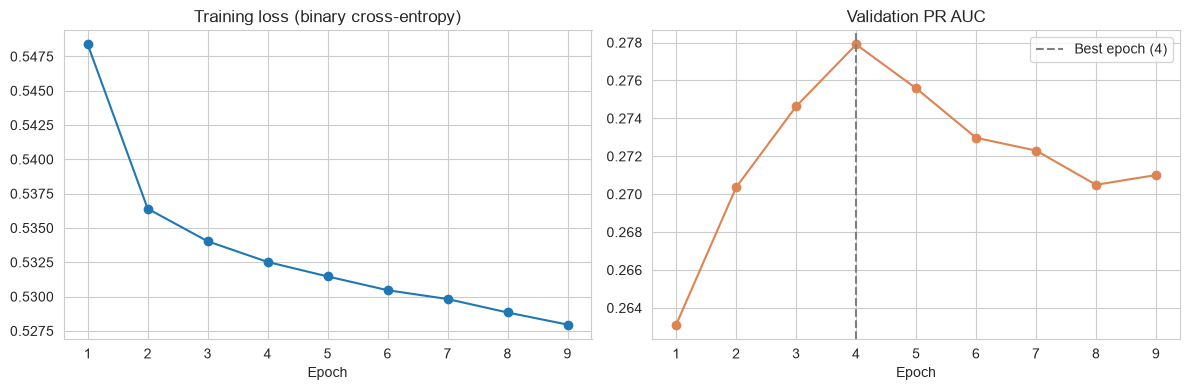

In [10]:
mlp, history = train_model(train_t, val_t, seed=0)
best_epoch = int(history["val_PR_AUC"].idxmax()) + 1
print("Best epoch:", best_epoch, " validation PR AUC:", round(history["val_PR_AUC"].max(), 4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history["epoch"], history["train_loss"], marker="o")
axes[0].set_title("Training loss (binary cross-entropy)")
axes[0].set_xlabel("Epoch")
axes[1].plot(history["epoch"], history["val_PR_AUC"], marker="o", color="#DD8452")
axes[1].axvline(best_epoch, color="grey", linestyle="--", label=f"Best epoch ({best_epoch})")
axes[1].set_title("Validation PR AUC")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.savefig("figures/learning_curves.png", dpi=150)
plt.show()

### 7.1 Stability across random seeds

In [11]:
seed_rows = []
for seed in range(5):
    m, h = train_model(train_t, val_t, seed=seed)
    p = predict_proba(m, test_t)
    seed_rows.append({"seed": seed, "epochs_trained": len(h), "val_PR_AUC": h["val_PR_AUC"].max(),
                      "test_PR_AUC": average_precision_score(y_test, p), "test_ROC_AUC": roc_auc_score(y_test, p)})
seed_table = pd.DataFrame(seed_rows)
display(seed_table.round(4))
print("Test PR AUC: mean %.4f, std %.4f" % (seed_table["test_PR_AUC"].mean(), seed_table["test_PR_AUC"].std()))

,seed,epochs_trained,val_PR_AUC,test_PR_AUC,test_ROC_AUC
0,0,9,0.2779,0.3858,0.6526
1,1,13,0.2730,0.3831,0.6526
2,2,8,0.2712,0.3864,0.6488
3,3,11,0.2720,0.3804,0.6512
4,4,8,0.2709,0.3868,0.6534


Test PR AUC: mean 0.3845, std 0.0027


## 8. Ablation study

In [12]:
no_history = [c for c in numeric_features if c not in history_features]

def make_variant(num_cols, cat_cols):
    return [make_tensors(d, num_cols, cat_cols) for d in (train, val, test)]

variants = {
    "Full model (embeddings)":    dict(data=make_variant(numeric_features, categorical_features), mode="embedding"),
    "One-hot instead of embeddings": dict(data=make_variant(numeric_features, categorical_features), mode="onehot"),
    "No categorical features":     dict(data=make_variant(numeric_features, []), mode="none", cat_cols=[]),
    "No history features":         dict(data=make_variant(no_history, categorical_features), mode="embedding"),
    "No dropout / weight decay":   dict(data=make_variant(numeric_features, categorical_features), mode="embedding",
                                        dropout=0.0, weight_decay=0.0),
}

ablation_rows = []
for name, v in variants.items():
    tr, va, te = v.pop("data")
    for seed in range(5):
        m, h = train_model(tr, va, seed=seed, **v)
        p = predict_proba(m, te)
        ablation_rows.append({"variant": name, "seed": seed, "val_PR_AUC": h["val_PR_AUC"].max(),
                              "test_PR_AUC": average_precision_score(y_test, p), "test_ROC_AUC": roc_auc_score(y_test, p)})

ablation = (pd.DataFrame(ablation_rows).groupby("variant", sort=False)
            .agg(val_PR_AUC=("val_PR_AUC", "mean"), test_PR_AUC=("test_PR_AUC", "mean"),
                 test_PR_AUC_std=("test_PR_AUC", "std"), test_ROC_AUC=("test_ROC_AUC", "mean")))
ablation.round(4)

,val_PR_AUC,test_PR_AUC,test_PR_AUC_std,test_ROC_AUC
variant,,,,
Full model (embeddings),0.2730,0.3845,0.0027,0.6517
One-hot instead of embeddings,0.2691,0.3862,0.0037,0.6565
No categorical features,0.2725,0.3857,0.0041,0.6553
No history features,0.2679,0.3575,0.0017,0.6248
No dropout / weight decay,0.2687,0.3826,0.0061,0.6499


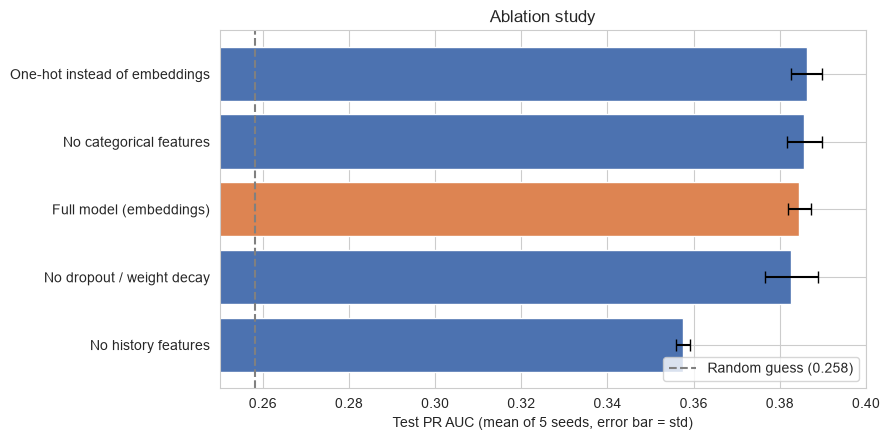

In [13]:
plt.figure(figsize=(9, 4.5))
order = ablation.sort_values("test_PR_AUC")
colors = ["#DD8452" if name == "Full model (embeddings)" else "#4C72B0" for name in order.index]
plt.barh(order.index, order["test_PR_AUC"], xerr=order["test_PR_AUC_std"], color=colors, capsize=4)
plt.axvline(y_test.mean(), color="grey", linestyle="--", label=f"Random guess ({y_test.mean():.3f})")
plt.xlim(0.25, 0.40)
plt.xlabel("Test PR AUC (mean of 5 seeds, error bar = std)")
plt.title("Ablation study")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("figures/ablation.png", dpi=150)
plt.show()

## 9. Evaluation on the test set

In [14]:
test_logits_mlp = predict_logits(mlp, test_t)
test_prob["MLP (embeddings)"] = 1 / (1 + np.exp(-test_logits_mlp))

def recall_at_precision(y_true, prob, min_precision=0.5):
    precision, recall, _ = precision_recall_curve(y_true, prob)
    return recall[precision >= min_precision].max()

rows = [{"model": "Random guess", "PR_AUC": y_test.mean(), "ROC_AUC": 0.5, "recall@precision0.5": np.nan, "Brier": np.nan}]
for name, p in test_prob.items():
    rows.append({"model": name, "PR_AUC": average_precision_score(y_test, p), "ROC_AUC": roc_auc_score(y_test, p),
                 "recall@precision0.5": recall_at_precision(y_test, p), "Brier": brier_score_loss(y_test, p)})
comparison = pd.DataFrame(rows).set_index("model").round(4)
comparison

,PR_AUC,ROC_AUC,recall@precision0.5,Brier
model,,,,
Random guess,0.2583,0.5000,NaN,NaN
Logistic Regression,0.3761,0.6451,0.0587,0.2280
XGBoost,0.3908,0.6560,0.1107,0.2187
MLP (embeddings),0.3858,0.6526,0.0941,0.1815


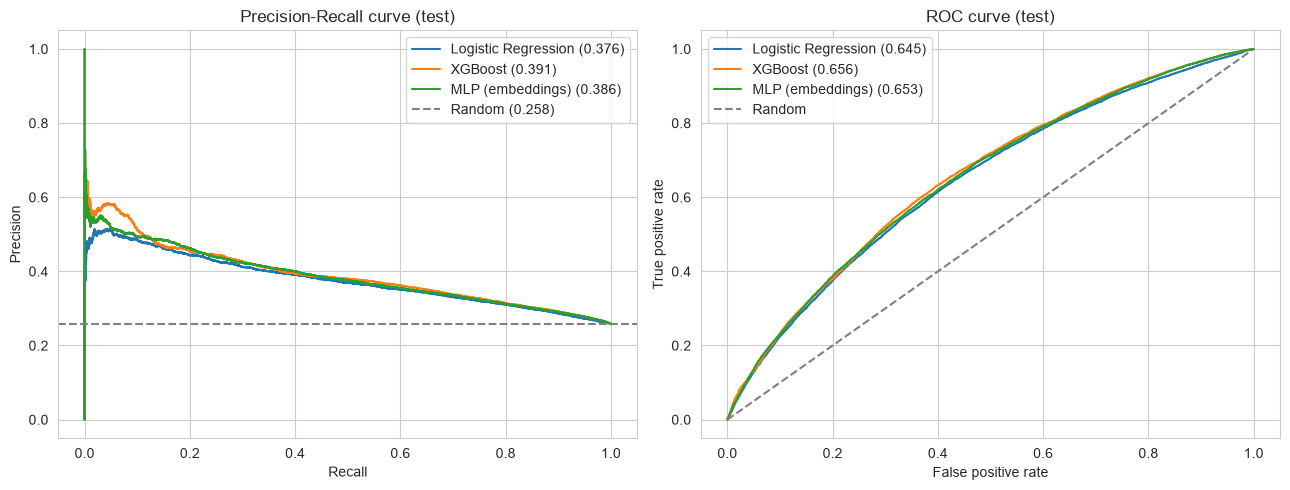

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, p in test_prob.items():
    precision, recall, _ = precision_recall_curve(y_test, p)
    axes[0].plot(recall, precision, label=f"{name} ({average_precision_score(y_test, p):.3f})")
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[1].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, p):.3f})")
axes[0].axhline(y_test.mean(), color="grey", linestyle="--", label=f"Random ({y_test.mean():.3f})")
axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precision"); axes[0].set_title("Precision-Recall curve (test)")
axes[1].plot([0, 1], [0, 1], color="grey", linestyle="--", label="Random")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate"); axes[1].set_title("ROC curve (test)")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.savefig("figures/pr_roc_curves.png", dpi=150)
plt.show()

## 10. Calibration (temperature scaling)

Temperature T = 0.785


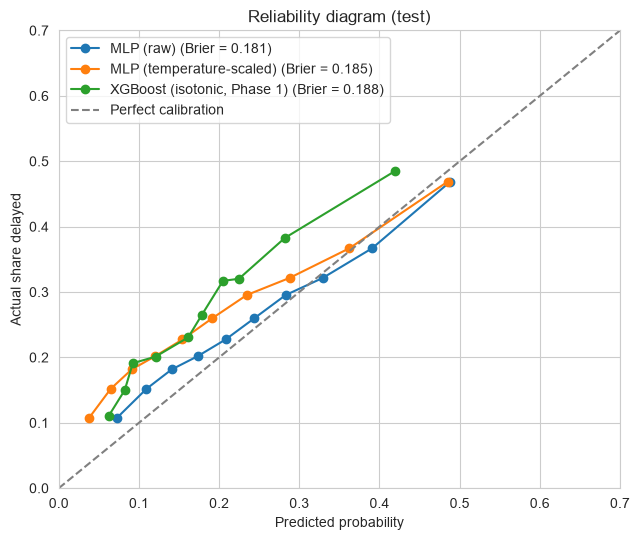

,Brier,mean predicted,actual_rate
MLP (raw),0.1815,0.2440,0.2583
MLP (temperature-scaled),0.1851,0.2029,0.2583
"XGBoost (isotonic, Phase 1)",0.1880,0.1749,0.2583


In [16]:
# Temperature scaling: divide the logits by one number T, chosen to minimise the log loss on the validation set
val_logits_mlp = torch.tensor(predict_logits(mlp, val_t))
log_t = torch.zeros(1, requires_grad=True)
opt = torch.optim.LBFGS([log_t], lr=0.1, max_iter=200)

def closure():
    opt.zero_grad()
    loss = F.binary_cross_entropy_with_logits(val_logits_mlp / log_t.exp(), torch.tensor(y_val, dtype=torch.float32))
    loss.backward()
    return loss

opt.step(closure)
T = log_t.exp().item()
mlp_test_temp = 1 / (1 + np.exp(-test_logits_mlp / T))
print(f"Temperature T = {T:.3f}")

from sklearn.calibration import calibration_curve
curves = {"MLP (raw)": test_prob["MLP (embeddings)"], "MLP (temperature-scaled)": mlp_test_temp,
          "XGBoost (isotonic, Phase 1)": xgb_test_cal}
plt.figure(figsize=(6.5, 5.5))
for name, p in curves.items():
    frac_pos, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    plt.plot(mean_pred, frac_pos, marker="o", label=f"{name} (Brier = {brier_score_loss(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], color="grey", linestyle="--", label="Perfect calibration")
plt.xlim(0, 0.7); plt.ylim(0, 0.7)
plt.xlabel("Predicted probability"); plt.ylabel("Actual share delayed"); plt.title("Reliability diagram (test)")
plt.legend()
plt.tight_layout()
plt.savefig("figures/calibration.png", dpi=150)
plt.show()

pd.DataFrame({"Brier": {n: brier_score_loss(y_test, p) for n, p in curves.items()},
              "mean predicted": {n: p.mean() for n, p in curves.items()}}).assign(actual_rate=y_test.mean()).round(4)

## 11. What did the embeddings learn?

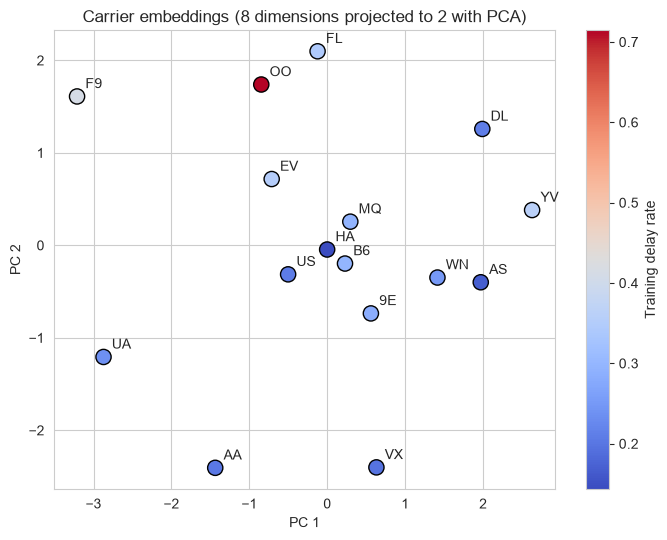

Correlation of PC 1 with carrier delay rate: -0.245


In [17]:
from sklearn.decomposition import PCA

carrier_names = sorted(vocab["carrier"], key=vocab["carrier"].get)
carrier_vectors = mlp.embeddings[0].weight.detach().numpy()[1:]        # skip id 0 (unseen)
coords = PCA(n_components=2).fit_transform(carrier_vectors)
carrier_rate = train.groupby("carrier")["delayed"].mean().reindex(carrier_names)

plt.figure(figsize=(7, 5.5))
sc = plt.scatter(coords[:, 0], coords[:, 1], c=carrier_rate, cmap="coolwarm", s=120, edgecolor="black")
for (x, y), name in zip(coords, carrier_names):
    plt.annotate(name, (x, y), textcoords="offset points", xytext=(6, 6))
plt.colorbar(sc, label="Training delay rate")
plt.title("Carrier embeddings (8 dimensions projected to 2 with PCA)")
plt.xlabel("PC 1"); plt.ylabel("PC 2")
plt.tight_layout()
plt.savefig("figures/carrier_embeddings.png", dpi=150)
plt.show()

print("Correlation of PC 1 with carrier delay rate:", round(np.corrcoef(coords[:, 0], carrier_rate)[0, 1], 3))

## 12. What-if analysis: rescheduling high-risk flights

In [18]:
# Assumptions (offline, model-based, not causal):
#  1. Only flights in the top 10% of predicted risk on the test set are considered.
#  2. A flight may move by -2, -1, +1 or +2 hours on the same day; departures stay between 05:00 and 23:59
#     and the arrival must not cross midnight.
#  3. Arrival time moves by the same amount; route, carrier, date and the 7-day history stay the same.
#  Risk = the MLP's raw probabilities (best calibrated on the test set, see section 10).
#  4. Congestion is recomputed for the new hour (flights already scheduled then, plus the moved flight).
#  5. Flights are moved one at a time; crews, aircraft rotations, gates and passengers are ignored.
shifts = [-2, -1, 1, 2]
risk = test_prob["MLP (embeddings)"]
high = test[risk >= np.quantile(risk, 0.9)].copy()
high_risk = risk[risk >= np.quantile(risk, 0.9)]

options = {}
for s in shifts:
    moved = high.copy()
    moved["dep_hour"] = moved["dep_hour"] + s
    moved["arr_hour"] = moved["arr_hour"] + s
    add_cyclic(moved, "dep_hour", 24)
    add_cyclic(moved, "arr_hour", 24)
    counts = hour_counts.reindex(pd.MultiIndex.from_frame(moved[["date", "origin", "dep_hour"]])).fillna(0).values
    moved["origin_hour_flights"] = counts + 1
    p = predict_proba(mlp, make_tensors(moved))
    not_allowed = (moved["dep_hour"] < 5) | (moved["dep_hour"] > 23) | (moved["arr_hour"] < 0) | (moved["arr_hour"] > 23)
    p[not_allowed.values] = np.nan
    options[s] = p

options = pd.DataFrame(options, index=high.index)
best_shift = options.idxmin(axis=1)
best_risk = options.min(axis=1)
reduction = high_risk - best_risk.values

print("High-risk flights:", len(high), f"(risk >= {np.quantile(risk, 0.9):.3f})")
print("Mean predicted risk now:          ", round(high_risk.mean(), 3))
print("Mean risk at best alternative slot:", round(best_risk.mean(), 3))
print("Flights whose risk drops by 5+ percentage points:", f"{(reduction >= 0.05).mean():.1%}")
best_shift.value_counts().rename("flights").rename_axis("best shift (hours)").sort_index()

High-risk flights: 5400 (risk >= 0.429)
Mean predicted risk now:           0.488
Mean risk at best alternative slot: 0.442
Flights whose risk drops by 5+ percentage points: 40.7%


best shift (hours)
-2    3842
-1     355
 1     630
 2     573
Name: flights, dtype: int64

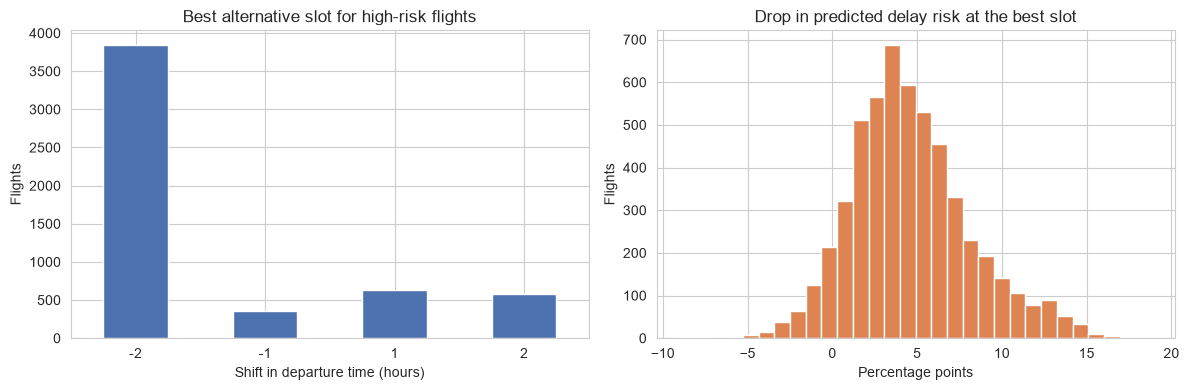

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
best_shift.value_counts().sort_index().plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Best alternative slot for high-risk flights")
axes[0].set_xlabel("Shift in departure time (hours)"); axes[0].set_ylabel("Flights")
axes[0].tick_params(axis="x", rotation=0)
axes[1].hist(reduction * 100, bins=30, color="#DD8452")
axes[1].set_title("Drop in predicted delay risk at the best slot")
axes[1].set_xlabel("Percentage points"); axes[1].set_ylabel("Flights")
plt.tight_layout()
plt.savefig("figures/what_if.png", dpi=150)
plt.show()